# Question 9 — Concentration en salle, entrées et comportements hors norme

## 1. Chargement des données 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

billets = pd.read_csv('../data/processed/billets_clean.csv')
evenements = pd.read_csv('../data/processed/evenements_clean.csv', parse_dates=['date'])

print("billets :", billets.shape)
print("evenements :", evenements.shape)

billets : (700, 15)
evenements : (96, 9)


## 2. Concentration des spéctateurs dans la salle 

In [2]:
billets['distance_centre'] = np.sqrt(billets['x_salle_m']**2 + billets['y_salle_m']**2)

anneaux = billets.groupby('zone')['distance_centre'].agg(['min','max'])

anneaux.columns = ['rayon_min', 'rayon_max']

anneaux['surface'] = np.pi * (anneaux['rayon_max']**2 - anneaux['rayon_min']**2)

display(anneaux.round(1))

,rayon_min,rayon_max,surface
zone,,,
fosse,0.0,18.0,1012.4
gradin bas,24.0,37.9,2709.9
gradin haut,44.0,62.0,5994.3
loge,20.0,23.8,525.1


Chaque zone forme un anneau autour du centre ; sa surface est estimée à partir des distances minimale et maximale observées (π × (R² − r²)). Les rayons sont tirés des billets de l'échantillon : la vraie limite des zones peut être légèrement plus large.

In [3]:
densite = pd.DataFrame({
    'part_billets': billets['zone'].value_counts(normalize= True),
    'part_surface': anneaux['surface'] / anneaux['surface'].sum()
})
densite['densite_relative'] = densite['part_billets'] / densite['part_surface']

display(densite.sort_values('densite_relative', ascending=False).round(3))

,part_billets,part_surface,densite_relative
zone,,,
fosse,0.283,0.099,2.862
gradin bas,0.347,0.265,1.312
loge,0.064,0.051,1.254
gradin haut,0.306,0.585,0.522


La densité relative rapporte la part des spectateurs d'une zone à la part de surface qu'elle occupe (1 = répartition uniforme). La fosse est près de 3 fois plus dense que la moyenne de la salle (2,86), alors que le gradin haut, qui occupe 58 % de la surface pour 31 % des spectateurs, l'est deux fois moins (0,52). Le gradin bas compte le plus de billets, mais c'est la fosse qui concentre le public. Limite : la surface est mesurée au sol, alors que les gradins sont en pente.

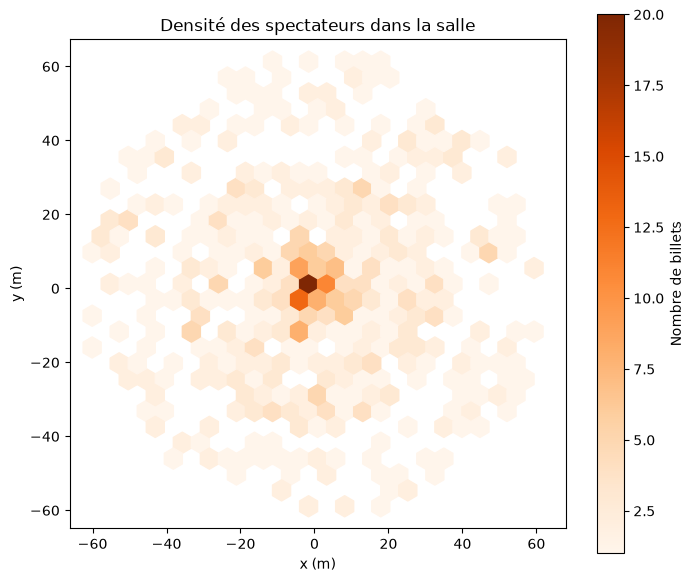

In [4]:
plt.figure(figsize=(8, 7))
plt.hexbin(billets['x_salle_m'], billets['y_salle_m'], gridsize=25, cmap='Oranges', mincnt=1)
plt.colorbar(label="Nombre de billets")
plt.gca().set_aspect('equal')
plt.title("Densité des spectateurs dans la salle")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.show()

La concentration de la fosse n'est pas uniforme : elle forme un point chaud au centre de la salle (jusqu'à une vingtaine de billets par hexagone), alors que le reste de la salle est peu chargé.

## 3. Entrées et Saturation

In [5]:
billets['angle'] = np.degrees(np.arctan2(billets['y_salle_m'], billets['x_salle_m'])) % 360

display(billets['angle'].describe().round(1))

count    700.0
mean     179.5
std      104.7
min        0.0
25%       86.9
50%      178.6
75%      269.1
max      359.8
Name: angle, dtype: float64

In [6]:
angle_decale = (billets['angle'] + 45) % 360

billets['entree'] = pd.cut(angle_decale,
                           bins=[0, 90, 180, 270, 360],
                           labels=['Est', 'Nord', 'Ouest', 'Sud'],
                           right=False)

print("Spectateurs par entrée")
display(billets['entree'].value_counts(normalize=True).round(3))

Spectateurs par entrée


entree
Est      0.257
Ouest    0.250
Nord     0.247
Sud      0.246
Name: proportion, dtype: float64

Hypothèse : 4 entrées (Nord, Est, Sud, Ouest), chaque spectateur passant par celle du secteur de sa place. Les spectateurs se répartissent presque également entre les 4 entrées (de 24,6 % à 25,7 %) : aucune n'est surchargée en volume sur la soirée, une éventuelle saturation viendra donc des horaires d'arrivée.

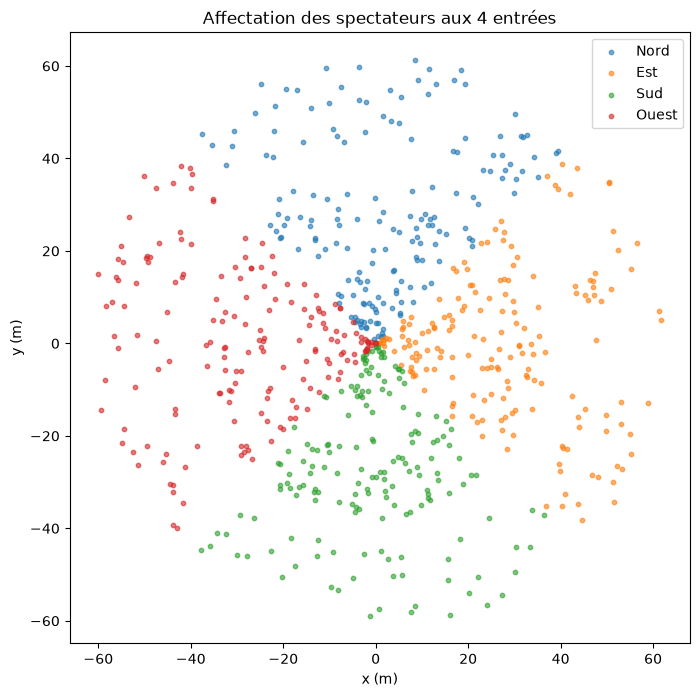

In [7]:
plt.figure(figsize=(8, 8))

for entree in ['Nord', 'Est', 'Sud', 'Ouest']:
    sous_ensemble = billets[billets['entree'] == entree]
    plt.scatter(sous_ensemble['x_salle_m'], sous_ensemble['y_salle_m'], s=10, alpha=0.6, label=entree)

plt.gca().set_aspect('equal')
plt.title("Affectation des spectateurs aux 4 entrées")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.legend()
plt.show()

La carte confirme le découpage : chaque entrée correspond à un quart de la salle, de la fosse au gradin haut.

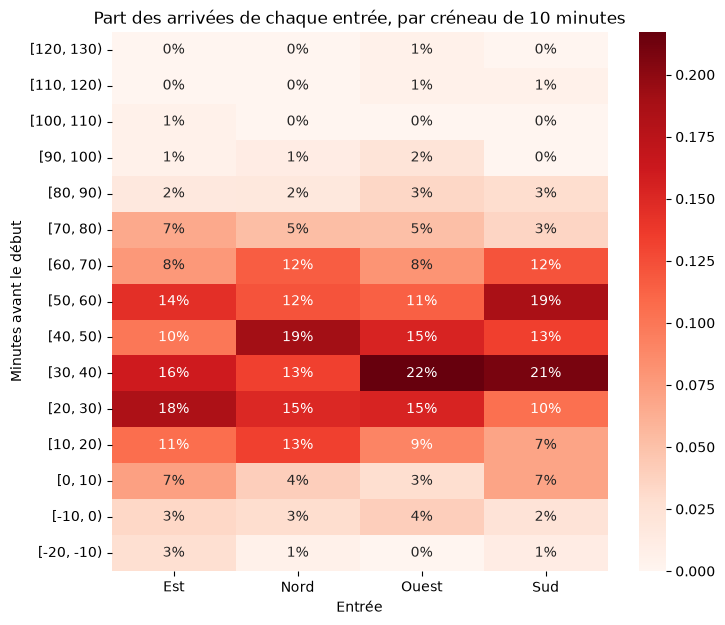

In [8]:
billets['creneau'] = pd.cut(billets['arrivee_min_avant'],
                            bins=np.arange(-20, 131, 10),
                            right=False)

arrivees = pd.crosstab(billets['creneau'], billets['entree'], normalize='columns')


plt.figure(figsize=(8, 7))
sns.heatmap(arrivees.iloc[::-1], annot=True, fmt='.0%', cmap='Reds')
plt.title("Part des arrivées de chaque entrée, par créneau de 10 minutes")
plt.xlabel("Entrée")
plt.ylabel("Minutes avant le début")
plt.show()

Pour toutes les entrées, l'essentiel des arrivées a lieu entre 20 et 60 minutes avant le début ; les retardataires restent marginaux (2 à 6 %). Les pics diffèrent selon l'entrée : Ouest et Sud entre 30 et 40 minutes (22 % et 21 % de leurs spectateurs), Nord entre 40 et 50 minutes, Est plus tard, entre 20 et 30 minutes. Chaque entrée ne comptant qu'environ 175 billets, ces écarts sont des tendances : la forme générale du pic est solide, le détail par entrée l'est moins.

In [9]:
spectateurs_soiree = evenements['billets_vendus'].median()
print("Spectateurs pour une soirée type (médiane) :", spectateurs_soiree)

part_entree = billets['entree'].value_counts(normalize=True)
part_pic = arrivees.max()
creneau_pic = arrivees.idxmax()

flux = pd.DataFrame({
    'creneau_pic': creneau_pic,
    'part_au_pic': part_pic.round(3),
    'spectateurs_entree': (spectateurs_soiree * part_entree).round(0),
})
flux['personnes_par_minute'] = (flux['spectateurs_entree'] * flux['part_au_pic'] / 10).round(0)

display(flux.sort_values('personnes_par_minute', ascending=False))

Spectateurs pour une soirée type (médiane) : 5639.0


,creneau_pic,part_au_pic,spectateurs_entree,personnes_par_minute
entree,,,,
Ouest,"[30, 40)",0.217,1410.0,31.0
Sud,"[30, 40)",0.209,1386.0,29.0
Nord,"[40, 50)",0.191,1394.0,27.0
Est,"[20, 30)",0.183,1450.0,27.0


Rapporté à une soirée médiane (5 639 spectateurs), le pic représente 27 à 31 personnes par minute et par entrée, l'Ouest étant la plus chargée (31 personnes par minute entre 30 et 40 minutes avant le début). Aucune entrée ne se distingue nettement en volume : la saturation est une question d'horaire, pas d'entrée.

In [10]:
debit_portique = 20   # hypothèse : personnes par minute qu'un portique fait passer

scenarios = {
    'Soirée médiane': spectateurs_soiree,
    'Complet 6 500': 6500,
    'Complet 9 800': 9800,
    'Complet 15 800': 15800,
}

lignes = []
for nom, spectateurs in scenarios.items():
    for entree in flux.index:
        personnes_minute = spectateurs * part_entree[entree] * part_pic[entree] /10
        lignes.append({
            'scenario': nom,
            'entree': entree,
            'creneau_pic': creneau_pic[entree],
            'personnes_par_minute': round(personnes_minute),
            'portiques': int(np.ceil(personnes_minute / debit_portique)),
        })

dispositif = pd.DataFrame(lignes)

print("Portiques à ouvrir au pic, par entrée et par scénario")
display(dispositif.pivot(index='entree', columns='scenario', values='portiques')
        [list(scenarios.keys())])

Portiques à ouvrir au pic, par entrée et par scénario


scenario,Soirée médiane,Complet 6 500,Complet 9 800,Complet 15 800
entree,,,,
Est,2,2,3,4
Nord,2,2,3,4
Ouest,2,2,3,5
Sud,2,2,3,5


Hypothèse de débit : un portique fait passer 20 personnes par minute (à ajuster avec la valeur réelle de l'exploitation). Jusqu'à 6 500 spectateurs, 2 portiques par entrée suffisent au pic ; une soirée complète en 9 800 places en demande 3 par entrée, et une soirée complète en 15 800 places 5 à l'Ouest et au Sud, 4 au Nord et à l'Est.

**Recommandation :** dimensionner l'accueil selon la configuration de la soirée et décaler l'ouverture des portiques supplémentaires selon le pic de chaque entrée (Nord 40-50 min avant le début, Ouest et Sud 30-40 min, Est 20-30 min), ce qui permet au même personnel de passer d'une entrée à l'autre.


## 4. Comportements d'achat et d'arrivée hors norme

In [11]:
def bornes_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col in ['achat_jours_avant', 'arrivee_min_avant']:
    bas, haut = bornes_iqr(billets[col])
    masque = (billets[col] < bas) | (billets[col] > haut)
    billets[f'extreme_{col}'] = masque
    print(f"{col} : normal entre {bas:.0f} et {haut:.0f} → {masque.sum()} billets hors norme")

achat_jours_avant : normal entre -36 et 112 → 25 billets hors norme
arrivee_min_avant : normal entre -26 et 106 → 3 billets hors norme


Selon la règle de l'IQR, 25 billets ont été achetés anormalement tôt (plus de 112 jours avant l'événement, jusqu'à 187) et 3 spectateurs sont arrivés anormalement en avance (plus de 106 minutes) ; aucun retard n'est hors norme, les retardataires (jusqu'à 20 minutes) restent dans la variation normale.

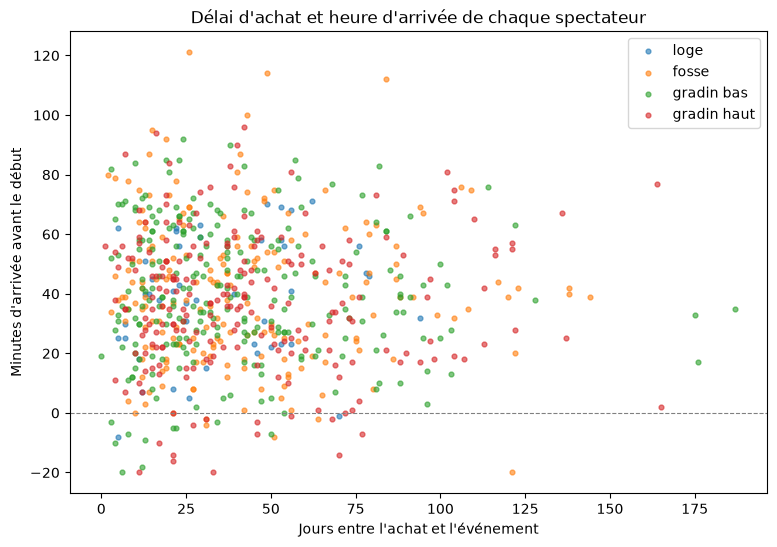

In [12]:
plt.figure(figsize=(9, 6))

for zone in billets['zone'].unique():
    sous_ensemble = billets[billets['zone'] == zone]
    plt.scatter(sous_ensemble['achat_jours_avant'], sous_ensemble['arrivee_min_avant'], s=12, alpha=0.6, label=zone)

plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.title("Délai d'achat et heure d'arrivée de chaque spectateur")
plt.xlabel("Jours entre l'achat et l'événement")
plt.ylabel("Minutes d'arrivée avant le début")
plt.legend()
plt.show()

Les spectateurs forment un seul nuage, sans groupe isolé : le délai d'achat et l'heure d'arrivée sont peu liés, et seuls quelques points isolés se détachent (achats très anticipés, arrivées près de 2 heures en avance).

In [13]:
variables = ['achat_jours_avant', 'arrivee_min_avant', 'prix_paye_eur']

# 1. Standardisation : chaque variable a une moyenne de 0 et un écart-type de 1
X = StandardScaler().fit_transform(billets[variables])

# 2. Distance de chaque billet à son k-ième plus proche voisin
k = 10
voisins = NearestNeighbors(n_neighbors=k + 1).fit(X)
distances, _ = voisins.kneighbors(X)
billets['score_isolement'] = distances[:, k]

# 3. Les 2 % de billets les plus isolés sont considérés comme anomalies
seuil = billets['score_isolement'].quantile(0.98)
billets['anomalie'] = billets['score_isolement'] > seuil

print("Billets détectés comme anomalies :", billets['anomalie'].sum())

print("\n Profil moyen : anomalies contre reste du public")
display(billets.groupby('anomalie')[variables + ['conso_bar_eur', 'age']].mean().round(1))

print("\n Répartition par zone des anomalies")
display(billets.loc[billets['anomalie'], 'zone'].value_counts())

print("\n Recoupement avec les indicateurs du nettoyage")
display(billets.loc[billets['anomalie'], ['invitation', 'prix_plancher', 'age_inconnu']].sum())

Billets détectés comme anomalies : 14

 Profil moyen : anomalies contre reste du public


,achat_jours_avant,arrivee_min_avant,prix_paye_eur,conso_bar_eur,age
anomalie,,,,,
False,40.5,38.8,69.5,7.1,35.8
True,108.6,59.1,81.0,7.9,34.0



 Répartition par zone des anomalies


zone
gradin bas     6
gradin haut    4
fosse          4
Name: count, dtype: int64


 Recoupement avec les indicateurs du nettoyage


invitation       0
prix_plancher    0
age_inconnu      2
dtype: int64

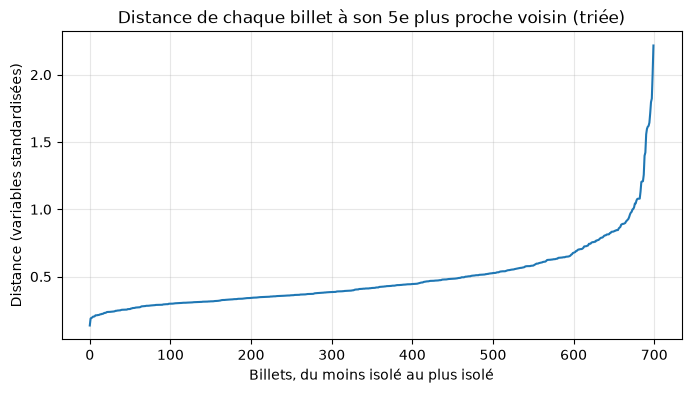

Distances aux percentiles 90, 95 et 98 : [0.77 0.9  1.21]


In [14]:
min_samples = 6 

voisins = NearestNeighbors(n_neighbors=min_samples).fit(X)
distances, _ = voisins.kneighbors(X)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.title(f"Distance de chaque billet à son {min_samples - 1}e plus proche voisin (triée)")
plt.xlabel("Billets, du moins isolé au plus isolé")
plt.ylabel("Distance (variables standardisées)")
plt.grid(alpha=0.3)
plt.show()

print("Distances aux percentiles 90, 95 et 98 :", np.percentile(k_distances, [90, 95, 98]).round(2))

Choix des paramètres de DBSCAN : `min_samples = 6` (environ deux fois le nombre de variables), et `eps` lu sur le graphe des distances au 5e plus proche voisin. La courbe reste plate pour la grande majorité des billets, puis se redresse brusquement autour de 1,0 (entre le 95e et le 98e percentile) : les billets au-delà de ce coude sont nettement plus isolés que les autres. `eps` est donc fixé à 1,0.

Choix des paramètres de DBSCAN : `min_samples = 6` (environ deux fois le nombre de variables), et `eps` lu sur le graphe des distances au 5e plus proche voisin. La courbe reste plate pour la grande majorité des billets, puis se redresse brusquement autour de 1,0 (entre le 95e et le 98e percentile) : les billets au-delà de ce coude sont nettement plus isolés que les autres. `eps` est donc fixé à 1,0.

In [15]:

eps = 1.0   

dbscan = DBSCAN(eps=eps, min_samples=min_samples)
billets['groupe_dbscan'] = dbscan.fit_predict(X)
billets['anomalie'] = billets['groupe_dbscan'] == -1

print("Groupes trouvés :", billets.loc[~billets['anomalie'], 'groupe_dbscan'].nunique())
print("Billets en bruit (anomalies) :", billets['anomalie'].sum())

print("\n Profil moyen : anomalies contre reste du public")
display(billets.groupby('anomalie')[variables + ['conso_bar_eur', 'age']].mean().round(1))

print("\n Répartition par zone des anomalies")
display(billets.loc[billets['anomalie'], 'zone'].value_counts())

print("\n Recoupement avec les indicateurs du nettoyage")
display(billets.loc[billets['anomalie'], ['invitation', 'prix_plancher', 'age_inconnu']].sum())

Groupes trouvés : 1
Billets en bruit (anomalies) : 13

 Profil moyen : anomalies contre reste du public


,achat_jours_avant,arrivee_min_avant,prix_paye_eur,conso_bar_eur,age
anomalie,,,,,
False,40.5,38.9,69.5,7.1,35.8
True,113.2,54.8,83.9,8.2,33.9



 Répartition par zone des anomalies


zone
gradin bas     6
gradin haut    4
fosse          3
Name: count, dtype: int64


 Recoupement avec les indicateurs du nettoyage


invitation       0
prix_plancher    0
age_inconnu      2
dtype: int64

DBSCAN (eps = 1,0, min_samples = 6) trouve un seul groupe : le public n'a qu'un comportement d'achat et d'arrivée « normal ». 13 billets (1,9 %) ne s'y rattachent pas et sont classés en bruit. Ils partagent le profil déjà isolé par le KNN : achat très anticipé (113 jours contre 41), arrivée plus précoce (55 minutes contre 39) et prix plus élevé (84 € contre 70 €). Ce ne sont ni des invitations ni des prix plancher : il ne s'agit pas d'erreurs, mais d'un profil de spectateurs très anticipateurs. Les variables de position ont été exclues, pour que la faible densité du gradin haut ne fasse pas passer ses spectateurs pour atypiques.

In [16]:
print("Test de robustesse : le profil des anomalies dépend-il de eps ?\n")

resultats = []
for eps_test in [eps * 0.8, eps, eps * 1.2]:
    labels = DBSCAN(eps=eps_test, min_samples=min_samples).fit_predict(X)
    detectees = labels == -1
    profil = billets.loc[detectees, variables].mean()
    resultats.append({
        'eps': round(eps_test, 2),
        'nb_groupes': len(set(labels) - {-1}),
        'nb_anomalies': detectees.sum(),
        'achat_jours_avant': round(profil['achat_jours_avant'], 1),
        'arrivee_min_avant': round(profil['arrivee_min_avant'], 1),
        'prix_paye_eur': round(profil['prix_paye_eur'], 1),
    })

display(pd.DataFrame(resultats))

print("\n Pour comparaison, reste du public :")
display(billets.loc[~billets['anomalie'], variables].mean().round(1))

Test de robustesse : le profil des anomalies dépend-il de eps ?



,eps,nb_groupes,nb_anomalies,achat_jours_avant,arrivee_min_avant,prix_paye_eur
0,0.8,2,22,91.5,52.8,86.7
1,1.0,1,13,113.2,54.8,83.9
2,1.2,1,8,148.2,41.5,71.6



 Pour comparaison, reste du public :


achat_jours_avant    40.5
arrivee_min_avant    38.9
prix_paye_eur        69.5
dtype: float64

Test de robustesse : avec eps = 0,8, 1,0 et 1,2, les billets en bruit achètent toujours bien plus tôt que le reste du public (de 92 à 148 jours contre 41), et l'écart grandit à mesure que le seuil devient exigeant : l'achat très anticipé est le trait robuste de ces spectateurs. L'arrivée plus précoce et le prix plus élevé, nets à 0,8 et 1,0, disparaissent pour les 8 cas les plus extrêmes (eps = 1,2) : ce sont des tendances associées, pas des caractéristiques constantes. Le découpage en 2 groupes à eps = 0,8 disparaît dès eps = 1,0 : il dépend du réglage et ne traduit pas deux comportements distincts.

## 5. Conclusion

### Où se concentrent les spectateurs ?
La **fosse** est la zone la plus dense : elle occupe 10 % de la surface de la salle mais accueille 28 % des spectateurs, soit une densité **près de 3 fois supérieure** à la moyenne (2,86), avec un point chaud au centre. À l'inverse, le **gradin haut** occupe 58 % de la surface pour 31 % des spectateurs : il est **deux fois moins dense** (0,52).

### Quelles entrées saturent ?
Hypothèse : 4 entrées (Nord, Est, Sud, Ouest), chaque spectateur passant par celle du secteur de sa place.
- En **volume**, aucune entrée n'est surchargée : chacune reçoit environ 25 % des spectateurs.
- La saturation est une question d'**horaire** : l'essentiel des arrivées a lieu entre 20 et 60 minutes avant le début, avec un pic décalé selon l'entrée (Nord 40-50 min, Ouest et Sud 30-40 min, Est 20-30 min).
- Au pic, une soirée médiane (5 639 spectateurs) représente **27 à 31 personnes par minute et par entrée** ; une soirée complète en 15 800 places, environ **85 personnes par minute** à l'Ouest.

### Quels comportements sortent de l'ordinaire ?
Aucun comportement d'achat ou d'arrivée ne relève de l'erreur ou de la fraude. Les retards restent modérés (jusqu'à 20 minutes) et dans la variation normale. DBSCAN ne trouve qu'**un seul groupe** de comportement : le public n'a pas plusieurs façons d'acheter et d'arriver nettement séparées. Deux méthodes vues en cours, **KNN et DBSCAN**, isolent environ 2 % de spectateurs dont le trait commun et robuste est l'**achat très anticipé** : environ 110 jours avant l'événement, contre 41 en moyenne, et jusqu'à 5 mois pour les cas les plus extrêmes. Ils ont **tendance** à payer plus cher et à arriver plus tôt, mais ces deux traits ne se retrouvent pas chez les cas les plus extrêmes. Ce ne sont ni des invitations ni des prix plancher.

### Recommandations
1. **Dimensionner l'accueil selon la configuration de la soirée** (hypothèse : 20 personnes par minute et par portique) :

| Configuration | Portiques par entrée au pic |
|---|---|
| Jusqu'à 6 500 spectateurs | 2 |
| Complet 9 800 places | 3 |
| Complet 15 800 places | 5 à l'Ouest et au Sud, 4 au Nord et à l'Est |

2. **Décaler l'ouverture des portiques supplémentaires** selon le pic de chaque entrée (Nord en premier, Est en dernier), pour que le même personnel passe d'une entrée à l'autre.
3. **Renforcer le placement et la sécurité en fosse**, où la densité est la plus forte, en particulier au centre.
4. **Cibler les spectateurs qui réservent très tôt** avec des préventes, avant-premières ou abonnements : ils s'engagent plusieurs mois à l'avance. Aucune mesure de contrôle particulière n'est nécessaire.

### Limites
- Les entrées sont **déduites de la position** des spectateurs, faute de plan dans les données : le nombre et l'emplacement réels des entrées sont à confirmer avec l'exploitation.
- Le débit d'un portique (20 personnes par minute) est une **hypothèse** à remplacer par la valeur réelle.
- L'échantillon compte environ 175 billets par entrée : la forme générale du pic d'arrivées est solide, le détail entrée par entrée est une tendance.
- La densité est calculée sur une surface **au sol**, alors que les gradins sont en pente ; les surfaces des zones sont estimées à partir des positions observées.
- Les paramètres de détection (k = 10 et seuil de 2 % pour le KNN, eps = 1,0 et min_samples = 6 pour DBSCAN) sont des choix. eps est lu sur le graphe des k-distances, et le test de robustesse (eps de 0,8 à 1,2) montre que seul l'achat très anticipé est un trait constant des anomalies ; l'arrivée précoce et le prix plus élevé sont des tendances.